# Cours 4 — Graphes et processus logistiques (7 jeux ERP)

**M2 Data Science · Data Mining · Travail de groupe · Domaine logistique**

Sept fichiers ERP sources : partenaires, installations, bons de réception, mouvements correctifs, inventaire mensuel, **lignes de commandes d’achat**, **expéditions**. Les calculs utilisent exclusivement les données ERP ; tous les signaux sont des *hypothèses à vérifier*, jamais des preuves de fraude.

## 1. Graphe hétérogène transactionnel

Le cours 4 présente `G=(V,E)`, direction/poids, degré, densité, centralités, communautés et process mining. Les **nœuds sont typés et namespacés** : partenaires, sites, lignes de commandes, réceptions, expéditions, ajustements et relevés mensuels.

**Attention aux liens réellement observés :**
- réception → ligne PO : clé composite exacte;
- ajustement → réception / expédition : clé référencée exacte;
- expédition → ses expéditeur, destinataire, transporteur, sites origine/destination ;
- ligne PO → fournisseur / site commandant.

Aucune arête *expédition ↔ réception* n’est créée car aucun champ ne l’établit explicitement.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'data/raw').exists(): ROOT=ROOT.parent
assert (ROOT/'data/raw').exists(), "Ouvrir le notebook depuis la racine du dépôt ou son répertoire notebooks/"
SEED=42
pd.set_option('display.max_columns',35)
pd.set_option('display.max_colwidth',85)
import networkx as nx
from collections import Counter
D=ROOT/'data/part1_clean';OUT=ROOT/'data/part4_graph';OUT.mkdir(parents=True,exist_ok=True)
def ld(t):return pd.read_csv(D/f'{t}_clean.csv')
bp=ld('erp_business_partners');fc=ld('erp_facilities');po=ld('purchase_order_lines');gr=ld('goods_receipts');sh=ld('shipments');ad=ld('inventory_adjustments');mo=ld('inventory_month_end')


## 2. Construction des nœuds et arêtes sourcées

Une arête porte `source_dataset`, `source_record_id`, `relation_type`, `event_date` et `evidence_strength=explicit_erp_reference`. Un identifiant absent dans sa table de référence donne lieu à un **contrôle de qualité**, pas à la création silencieuse d’une nouvelle entreprise.

In [2]:
nodes=[];edges=[]
def nid(kind,key):return f'ERP:{kind}:{key}'
def addnode(kind,key,label=None,**extra):
 if pd.isna(key):return None
 x=nid(kind,str(key));nodes.append({'node_id':x,'node_type':kind,'source_key':str(key),'label':str(label) if label is not None else str(key)})
 return x
def link(a,b,rel,ds,rid,date=None):
 if a and b:edges.append({'source_id':a,'target_id':b,'relation_type':rel,'source_dataset':ds,'source_record_id':rid,'event_date':date,'evidence_strength':'explicit_erp_reference'})
partners={r.partner_code:addnode('PARTNER',r.partner_code,r.partner_name) for r in bp.itertuples(index=False)}
sites={r.facility_code:addnode('FACILITY',r.facility_code,r.facility_name) for r in fc.itertuples(index=False)}
order_nodes={}
for r in po.itertuples(index=False):
 key=f'{r.purchase_order_number}:{int(r.purchase_order_line)}';z=addnode('ORDER_LINE',key);order_nodes[(r.purchase_order_number,r.purchase_order_line)]=z
 link(z,partners.get(r.supplier_partner_code),'ordered_from','purchase_order_lines',key,r.order_date)
 link(z,sites.get(r.ordering_facility_code),'ordered_at','purchase_order_lines',key,r.order_date)
for r in fc.itertuples(index=False):link(partners.get(r.operating_partner_code),sites.get(r.facility_code),'operates','erp_facilities',r.facility_code,r.opening_date)
receipt_nodes={}
for r in gr.itertuples(index=False):
 z=addnode('RECEIPT',r.receipt_number);receipt_nodes[r.receipt_number]=z
 link(z,order_nodes.get((r.purchase_order_number,r.purchase_order_line)),'receives_order_line','goods_receipts',r.receipt_number,r.receipt_date)
 link(z,partners.get(r.supplier_partner_code),'receipt_supplied_by','goods_receipts',r.receipt_number,r.receipt_date)
 link(z,sites.get(r.receiving_facility_code),'receipt_at','goods_receipts',r.receipt_number,r.receipt_date)
shipment_nodes={}
for r in sh.itertuples(index=False):
 key=f'{r.shipment_number}:{int(r.shipment_leg)}';z=addnode('SHIPMENT_LEG',key);shipment_nodes.setdefault(r.shipment_number,[]).append(z)
 for ent,role in [('sender_partner_code','sender'),('receiver_partner_code','receiver'),('carrier_partner_code','carrier')]:link(z,partners.get(getattr(r,ent)),role,'shipments',key,r.dispatch_time)
 link(z,sites.get(r.origin_facility_code),'departs_from','shipments',key,r.dispatch_time)
 link(z,sites.get(r.destination_facility_code),'arrives_at','shipments',key,r.arrival_time)
for r in ad.itertuples(index=False):
 z=addnode('ADJUSTMENT',r.adjustment_number)
 link(z,sites.get(r.facility_code),'adjustment_at','inventory_adjustments',r.adjustment_number,r.adjustment_date)
 if pd.notna(r.related_receipt_number):link(z,receipt_nodes.get(r.related_receipt_number),'adjusts_receipt','inventory_adjustments',r.adjustment_number,r.adjustment_date)
 if pd.notna(r.related_shipment_number):
  for s in shipment_nodes.get(r.related_shipment_number,[]):link(z,s,'adjusts_shipment','inventory_adjustments',r.adjustment_number,r.adjustment_date)
for i,r in enumerate(mo.itertuples(index=False)):
 key=f'{r.facility_code}:{r.reporting_month}:{r.item_category}:{r.unit}'
 z=addnode('MONTH_END',key)
 link(z,sites.get(r.facility_code),'stock_at','inventory_month_end',key,r.reporting_month)
nd=pd.DataFrame(nodes).drop_duplicates('node_id');ed=pd.DataFrame(edges).drop_duplicates()
valid=set(nd.node_id);assert ed.source_id.isin(valid).all() and ed.target_id.isin(valid).all()
nd.to_csv(OUT/'erp_graph_nodes.csv',index=False);ed.to_csv(OUT/'erp_graph_edges.csv',index=False)
print('Nœuds:',len(nd),'arêtes explicites:',len(ed));display(nd.node_type.value_counts());display(ed.relation_type.value_counts().head(14))


Nœuds: 2460 arêtes explicites: 6110


node_type
ORDER_LINE      650
RECEIPT         610
MONTH_END       500
SHIPMENT_LEG    450
ADJUSTMENT      140
PARTNER          80
FACILITY         30
Name: count, dtype: int64

relation_type
ordered_from           650
ordered_at             650
receives_order_line    610
receipt_at             610
receipt_supplied_by    610
stock_at               500
sender                 450
arrives_at             450
receiver               450
departs_from           450
carrier                450
adjustment_at          140
adjusts_shipment        37
operates                30
Name: count, dtype: int64

## 3. Degrés, densité, intermédiarité et communautés

La centralité représente une **position dans la structure enregistrée**. Une installation très active est naturellement centrale. Louvain regroupe des nœuds selon leur connexité ; un cluster n'est ni une organisation criminelle ni un signe de causalité. Les liens transactionnels orientés sont conservés dans `erp_graph_edges.csv`, les mesures structurelles sont calculées sur une vue simple non orientée.

Densité du graphe non orienté: 0.002005 ; composantes: 1


,node_id,node_type,degree,betweenness_approx,community_id
80,ERP:FACILITY:FCL-1011,FACILITY,422,0.257199,23
77,ERP:PARTNER:BP-30078,PARTNER,399,0.258966,23
85,ERP:FACILITY:FCL-1010,FACILITY,335,0.180933,4
82,ERP:FACILITY:FCL-1019,FACILITY,301,0.122903,3
86,ERP:FACILITY:FCL-1007,FACILITY,245,0.068152,23
83,ERP:FACILITY:FCL-1020,FACILITY,224,0.154444,20
81,ERP:FACILITY:FCL-1024,FACILITY,135,0.055442,14
87,ERP:FACILITY:FCL-1030,FACILITY,131,0.039602,1
90,ERP:FACILITY:FCL-1027,FACILITY,119,0.091019,15
46,ERP:PARTNER:BP-30047,PARTNER,108,0.032220,23


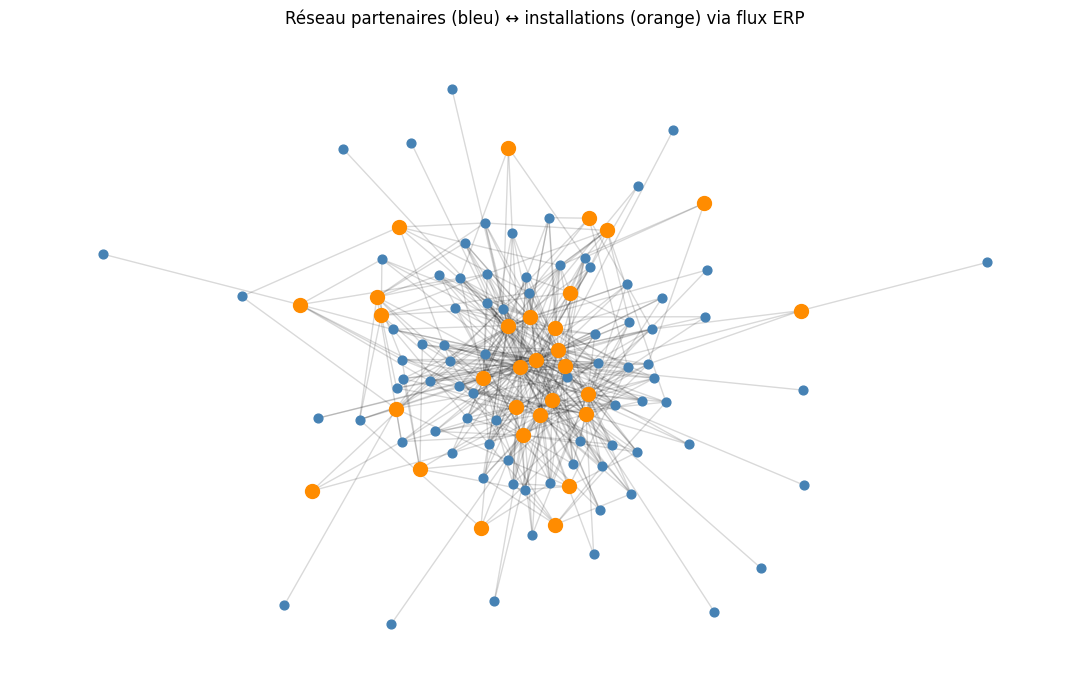

In [3]:
G=nx.Graph();G.add_nodes_from(nd.node_id)
for r in ed.itertuples(index=False):G.add_edge(r.source_id,r.target_id)
print('Densité du graphe non orienté:',round(nx.density(G),6),'; composantes:',nx.number_connected_components(G))
degree=dict(G.degree());between=nx.betweenness_centrality(G,k=min(100,len(G)),seed=SEED)
try:communities=nx.community.louvain_communities(G,seed=SEED)
except (AttributeError,ImportError):communities=list(nx.community.greedy_modularity_communities(G))
comm_map={k:i for i,group in enumerate(communities) for k in group}
nd['degree']=nd.node_id.map(degree);nd['betweenness_approx']=nd.node_id.map(between)
nd['community_id']=nd.node_id.map(comm_map)
nd.to_csv(OUT/'erp_graph_nodes.csv',index=False)
display(nd.sort_values('degree',ascending=False)[['node_id','node_type','degree','betweenness_approx','community_id']].head(12))
# Figure du graphe opérationnel PARTNER-FACILITY, bien plus lisible que le graphe transactionnel complet.
small=nx.Graph()
for r in fc.itertuples(index=False):small.add_edge(nid('PARTNER',r.operating_partner_code),nid('FACILITY',r.facility_code))
for r in gr.itertuples(index=False):small.add_edge(nid('PARTNER',r.supplier_partner_code),nid('FACILITY',r.receiving_facility_code))
for r in sh.itertuples(index=False):
 small.add_edge(nid('PARTNER',r.sender_partner_code),nid('FACILITY',r.origin_facility_code))
 small.add_edge(nid('PARTNER',r.receiver_partner_code),nid('FACILITY',r.destination_facility_code))
layout=nx.spring_layout(small,seed=SEED);plt.figure(figsize=(11,7));nx.draw_networkx_edges(small,layout,alpha=.15)
for typename,color,size in [('PARTNER','steelblue',40),('FACILITY','darkorange',100)]:
 subset=[v for v in small if v.startswith(f'ERP:{typename}:')];nx.draw_networkx_nodes(small,layout,nodelist=subset,node_color=color,node_size=size)
plt.title('Réseau partenaires (bleu) ↔ installations (orange) via flux ERP');plt.axis('off');plt.tight_layout();(ROOT/'figures').mkdir(exist_ok=True);plt.savefig(ROOT/'figures/cours4_network_7.png',dpi=130);plt.show()


## 4. Process mining : séquences effectivement datées

**Cas PO** : date de commande puis réceptions liées par référence PO exacte, dont dates éventuellement antérieures (anomalie conservée). **Cas expédition** : départ puis arrivée quand connue, suivis d’ajustements qui référencent explicitement `shipment_number`. Les séquences sont triées chronologiquement pour calculer un directly-follows graph (DFG) ; cela ne « corrige » pas les ordres attendus. Les cas PO et shipment restent distincts, car aucune clé commune ne permet de fusionner leurs historiques.

Cas: 1100  / événements: 2180


,from_activity,to_activity,frequency,reverse_frequency,heuristic_dependency
0,order_placed,receipt_recorded,610,0,0.998363
1,shipment_dispatched,shipment_arrived,433,0,0.997696
2,shipment_arrived,inventory_adjusted,23,0,0.958333
3,inventory_adjusted,shipment_dispatched,14,0,0.933333


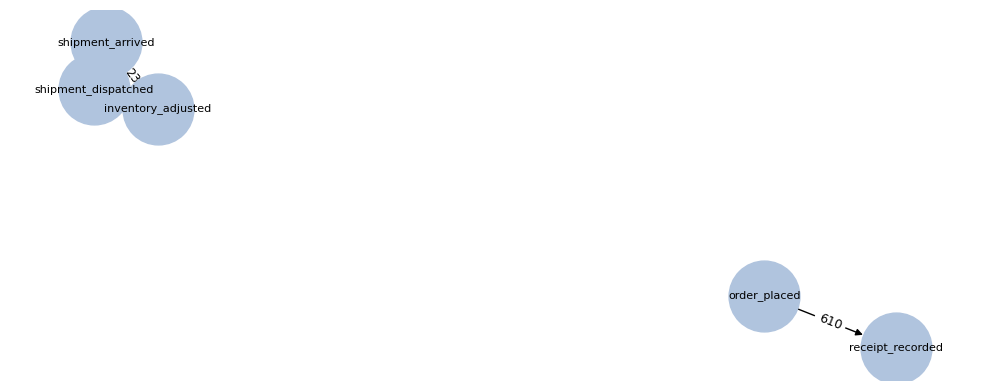

In [4]:
events=[]
def ev(case,rec,act,when,ds,facility):
 if pd.notna(when):events.append({'case_id':case,'event_id':str(rec),'activity':act,'timestamp':when,'source_dataset':ds,'facility_code':facility})
for r in po.itertuples(index=False):ev('PO:'+str(r.purchase_order_number)+':'+str(int(r.purchase_order_line)),r.purchase_order_number,'order_placed',r.order_date,'purchase_order_lines',r.ordering_facility_code)
for r in gr.itertuples(index=False):ev('PO:'+str(r.purchase_order_number)+':'+str(int(r.purchase_order_line)),r.receipt_number,'receipt_recorded',r.receipt_date,'goods_receipts',r.receiving_facility_code)
for r in sh.itertuples(index=False):
 case=f'SHP:{r.shipment_number}:{int(r.shipment_leg)}'
 ev(case,r.shipment_number,'shipment_dispatched',r.dispatch_time,'shipments',r.origin_facility_code)
 ev(case,r.shipment_number,'shipment_arrived',r.arrival_time,'shipments',r.destination_facility_code)
for r in ad.loc[ad.related_shipment_number.notna()].itertuples(index=False):
 for s in sh.loc[sh.shipment_number.eq(r.related_shipment_number)].itertuples(index=False):ev(f'SHP:{s.shipment_number}:{int(s.shipment_leg)}',r.adjustment_number,'inventory_adjusted',r.adjustment_date,'inventory_adjustments',r.facility_code)
log=pd.DataFrame(events)
log['time_sort']=pd.to_datetime(log.timestamp,errors='coerce',format='mixed');log=log.loc[log.time_sort.notna()].sort_values(['case_id','time_sort','event_id'])
log=log.drop(columns='time_sort');log.to_csv(OUT/'erp_process_event_log.csv',index=False)
counts=Counter()
for _,part in log.groupby('case_id'):
 seq=part.activity.tolist();counts.update(zip(seq,seq[1:]))
dfg=pd.DataFrame([{'from_activity':a,'to_activity':b,'frequency':v,'reverse_frequency':counts.get((b,a),0),'heuristic_dependency':(v-counts.get((b,a),0))/(v+counts.get((b,a),0)+1)} for (a,b),v in counts.items()])
dfg.to_csv(OUT/'erp_process_directly_follows.csv',index=False)
print('Cas:',log.case_id.nunique(),' / événements:',len(log));display(dfg.sort_values('frequency',ascending=False).head(14))
H=nx.DiGraph()
for r in dfg.itertuples(index=False):H.add_edge(r.from_activity,r.to_activity,weight=r.frequency)
if H.number_of_nodes():
 plt.figure(figsize=(10,4));pos=nx.spring_layout(H,seed=SEED)
 nx.draw_networkx(H,pos,node_size=2600,node_color='lightsteelblue',arrows=True,font_size=8)
 nx.draw_networkx_edge_labels(H,pos,edge_labels=nx.get_edge_attributes(H,'weight'),font_size=9)
 plt.axis('off');plt.tight_layout();plt.savefig(ROOT/'figures/cours4_process_7.png',dpi=130);plt.show()


## 5. Export commun pour le groupe

`erp_cross_domain_export.csv` contient **une alerte par ligne**, sourcée. `erp_graph_edges.csv` contient les relations exactes. Les référentiels site (nom, coordonnées, société opératrice), entreprise (immatriculation externe), expédition (numéro, intervenants, dates) et commande (numéro+ligne) servent de contrat de jointure.

Un lien dans un autre domaine doit être classé comme **clé exacte**, **rapprochement plausible à valider** ou **coïncidence**. Les rapprochements géographiques/temporels seuls ne créent pas une provenance matérielle.

In [5]:
find=pd.read_csv(ROOT/'data/part3_patterns/erp_review_findings.csv')
def eid(r):
 typ={'erp_business_partners':'PARTNER','erp_facilities':'FACILITY','goods_receipts':'RECEIPT','inventory_adjustments':'ADJUSTMENT','purchase_order_lines':'ORDER_LINE','shipments':'SHIPMENT_LEG','inventory_month_end':'MONTH_END'}.get(r.source_dataset,'RECORD')
 return nid(typ,r.record_id)
find['entity_id']=find.apply(eid,axis=1)
find['evidence_type']='ERP_rule_or_statistical_screen'
find.to_csv(OUT/'erp_cross_domain_export.csv',index=False)
reg=bp[['partner_code','partner_name','external_registration_number']].copy();reg['erp_entity_id']='ERP:PARTNER:'+reg.partner_code
reg.to_csv(OUT/'erp_registry_join_keys.csv',index=False)
fac=fc[['facility_code','facility_name','region','latitude','longitude','operating_partner_code']].copy();fac['erp_entity_id']='ERP:FACILITY:'+fac.facility_code
fac.to_csv(OUT/'erp_facility_join_keys.csv',index=False)
shipment_keys=sh[['shipment_number','shipment_leg','sender_partner_code','receiver_partner_code','carrier_partner_code','origin_facility_code','destination_facility_code','dispatch_time','arrival_time','item_category','declared_unit','authorization_class','shipment_status']].copy()
shipment_keys['erp_entity_id']='ERP:SHIPMENT_LEG:'+shipment_keys.shipment_number+':'+shipment_keys.shipment_leg.astype(int).astype(str)
shipment_keys.to_csv(OUT/'erp_shipment_join_keys.csv',index=False)
po_keys=po[['purchase_order_number','purchase_order_line','ordering_facility_code','supplier_partner_code','order_date','item_category','ordered_unit']].copy()
po_keys['erp_entity_id']='ERP:ORDER_LINE:'+po_keys.purchase_order_number+':'+po_keys.purchase_order_line.astype(int).astype(str)
po_keys.to_csv(OUT/'erp_purchase_order_join_keys.csv',index=False)
print('Référentiel graph:',len(nd),'nœuds /',len(ed),'arêtes /',len(find),'alertes /',len(shipment_keys),'lignes expédition')
display(Markdown('**Interprétation — Cours 4.** La chaîne commande→réception et les routes des expéditions sont maintenant explicites dans le graphe ; les références d’ajustements vers expéditions sont vérifiées. Les transitions DFG reflètent seulement les événements ERP horodatés, sans inventer les étapes de contrôle manquantes.'))


Référentiel graph: 2460 nœuds / 6110 arêtes / 140 alertes / 450 lignes expédition


**Interprétation — Cours 4.** La chaîne commande→réception et les routes des expéditions sont maintenant explicites dans le graphe ; les références d’ajustements vers expéditions sont vérifiées. Les transitions DFG reflètent seulement les événements ERP horodatés, sans inventer les étapes de contrôle manquantes.